# Data Analysis and Processing Notebook

Project : Addressing Inequity in Health Workforce in Thailand

Author : P. Sitthirat et al.

This notebook serves as a comprehensive guide for processing and analyzing health workforce data. It includes data cleaning and analysis.

**Objectives:**
- Apply data cleaning techniques.
- Analyse the ratio-to-population and inequity index.
- Visualize the changes along specific period.

**Requirements:**
Ensure the following libraries are installed before running the notebook:
`pip install -r scripts/requirements.txt`

## 1. Initial Setup and Library Imports

This cell initializes the notebook with necessary configurations and imports key libraries and custom modules for data processing, analysis, and specialty scraping.

### Features:
1. **IPython Extensions**:
   - `%load_ext autoreload`: Automatically reloads modules before executing cells, ensuring the latest code changes are applied.
   - `%autoreload 2`: Reloads all imported modules every time a cell is executed.

2. **Library Imports**:
   - `pandas`: For data manipulation and analysis.
   - `numpy`: For numerical operations.
   - `os`: For interacting with the operating system.
   - `itertools`: For creating efficient iterators.
   - `warnings`: To handle and suppress warnings.
   - `tqdm`: For progress bars in loops.
   - `matplotlib` and `plotly`: For building the graph

3. **Custom Modules** from `scripts` folder:
   - `process`: For data cleaning and processing.
   - `analyse`: For data analysis.

4. **Notebook Settings**:
   - `pd.set_option('future.no_silent_downcasting', True)`: Ensures that pandas raises warnings for downcasting operations.
   - `warnings.simplefilter('ignore', DeprecationWarning)`: Suppresses deprecation warnings for a cleaner output.
   - `plt.rcParams.update`: Standardise the graph style

### Code:
This configuration ensures an efficient and clean working environment for data analysis and processing.

In [2]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import os
import itertools
import warnings
from tqdm import tqdm
from scripts import process
from scripts import analyse
from scripts import scrp_hrh
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import plotly.graph_objects as go
import math
from IPython.display import clear_output

pd.set_option('display.max_rows', 300)
pd.set_option('future.no_silent_downcasting', True)
warnings.simplefilter('ignore', DeprecationWarning)

# Set a standardized style of graph
plt.rcParams.update({
    "font.size": 10,  # Standard font size for high-impact journals
    "font.family": "Arial",  # Standard font
    "axes.linewidth": 1,  # Line thickness
    "grid.alpha": 0.6,  # Grid transparency
    "grid.linestyle": "--",  # Grid style
})

## 2. Import Datasets: Hospital, Population, and Workforce Data

This section imports and processes the following datasets:
1. **Healthcare Facility Registry Dataset**: Dataset for health facility registry from the Office of the Permanent Secretary (OPS), Ministry of Public Health, Thailand. This dataset includes comprehensive information on the location, type, and administrative hierarchy of healthcare facilities and health regions
2. **National Population Registry Database**: Dataset for population and household numbers in each administrative area, disaggregated from country to village levels. This dataset is annually publicized by the Bureau of Registration Administration, Ministry of Interior, Thailand.
3. **Physician and Specialist Dataset**: Dataset for physician and specialist numbers, self-reported from each hospital in both public and private sectors.

---

### 2.1 Healthcare Facility Registry Dataset

Source : [Healthcare Facility Registry Dataset](https://hcode.moph.go.th/code/)

**Key Steps**:
1. Load hospital data using the `DataCleaning.clean` method.
2. Filter out hospitals with a status of "ยกเลิก" (cancelled).
3. Standardize the hospital code format.
4. **Retain Only Hospitals**:
   - Exclude other facilities like provincial/district health offices, private clinics, or units without admissions.
   - Include only specified hospital types:
     - Private hospitals.
     - Hospitals under OPS: General, Regional, and Community hospitals.
     - Hospitals under other ministries such as the Ministry of Higher Education, Science, Research and Innovation (MHERI), Ministry of Defence, and local government.
5. Save the cleaned dataset to `output/clean/hosp_cleaned.csv`.
6. Compute and display summary statistics for total, public, and private hospitals.

**Notes**:
- The cleaned dataset ensures a standardized and focused hospital registry for further analysis.
- The `DataCleaning.clean` method simplifies preprocessing by applying consistent cleaning rules.

In [3]:
# Import Thailand hospital data
hosp_file = 'hosp'
data_dir = 'data'
output_dir = 'output/clean'

hosp, hosp_raw, dict_path = process.DataCleaning.clean(hosp_file, data_dir, output_dir, clear=True)
hosp = hosp[(hosp['status'] != 'ยกเลิก')]
hosp = hosp[hosp['htype'].isin(['โรงพยาบาลเอกชน', 'โรงพยาบาล นอก สธ.', 'โรงพยาบาล นอก สป.สธ.', 'โรงพยาบาลชุมชน', 'โรงพยาบาลทั่วไป', 'โรงพยาบาลศูนย์', 'โรงพยาบาลส่งเสริมสุขภาพตำบล', 'ศูนย์บริการสาธารณสุข อปท.'])].copy()
hosp = hosp[~hosp['hcode'].isna()]
hosp['hcode'] = hosp['hcode'].apply(lambda x: x[2:-1]) #convert hcode from ="xxxxx" to xxxxx

hosp.to_csv('output/clean/hosp_cleaned.csv')

# Hospital descriptive
hosp_total = len(hosp)
hosp_public = len(hosp[hosp['hgroup']=='รัฐบาล'])
hosp_private = len(hosp[hosp['hgroup']=='เอกชน'])

print(
      "----------------------------------------------------",
      "\nTotal hospital:" , hosp_total,
      "\nTotal public hospital:", hosp_public,
      "\nTotal private hospital:", hosp_private,
      "\n----------------------------------------------------")

File name                : hosp
Path to data dictionary  : data/data_dict-hosp.xlsx
Path to cleaned dataset  : output/clean/hosp_cleaned.csv
---------------------------------------------------- 
Total hospital: 11791 
Total public hospital: 11330 
Total private hospital: 461 
----------------------------------------------------


### 2.2 National Population Registry Database

Source : [National Population Registry Database](https://stat.bora.dopa.go.th/new_stat/webPage/statByYear.php)

**Key Steps**:
1. Iterate over population files for the years 2014–2023.
2. Load each file and standardize column names using a data dictionary.
3. Process population data for the following levels:
   - **Country**: Extract national population data and save it to `output/clean/pop_country.csv`.
   - **Province**: Extract population data by province and save it to `output/clean/pop_prov.csv`.
   - **District**: Aggregate and clean data by district and save it to `output/clean/pop_dist.csv`.
   - **Health Region**: Map provinces to health regions [see details](https://en.wikipedia.org/wiki/Healthcare_in_Thailand), aggregate population data, and save it to `output/clean/pop_hregion.csv`. 

**Notes**:
- The dataset provides comprehensive population and household statistics, disaggregated from the country level to individual villages.
- The preprocessing ensures consistency across multiple years and enables multi-level analysis.
- The mapping of provinces to health regions enhances regional-level analysis for healthcare planning. This mapping is saved in `output/map/map_prov.csv` and can be reused for other analyses. It provides a standardized reference for associating provinces with their respective health regions, ensuring consistency in future opportunities or projects.

---

**Details of Mapping File (`map_prov.csv`)**:
- **Location**: `output/map/map_prov.csv`
- **Contents**:
  - `prov`: The official names of provinces in Thai.
  - `parameter_map`: Designations of the corresponding health regions.

**Utility**:
- This mapping file can be applied to other datasets requiring regional aggregation, such as healthcare facility datasets or disease surveillance data.
- It ensures a consistent framework for associating provinces with their health regions, saving time and reducing errors in future analyses.

In [4]:
# Import Thailand population data
hosp_file = 'pop'
data_dir = 'data/pop'
output_dir = 'output/clean'

years = range(2015,2025)

pop_country = pd.DataFrame()
pop_hregion = pd.DataFrame()
pop_prov = pd.DataFrame()
pop_dist = pd.DataFrame()

for year in years:
    
    hosp_file = f'data/pop/pop_{year}.xlsx'
    pop = pd.read_excel(hosp_file, sheet_name='pop')
    pop = process.DataCleaning.update_column_name(pop, 'data/pop/data_dict-pop.xlsx')

    pop['prov'] = pop['prov'].apply(lambda x: x if x in ['กรุงเทพมหานคร', 'ทั่วประเทศ'] else x[7:])
    pop['year'] = year
    
    # Create population dataset in country level
    country = pop[pop['prov_id'] == 0][['year', 'prov', 'pop']]
    pop_country = pd.concat([pop_country, country], ignore_index=True)
    pop_country.to_csv('output/clean/pop_country.csv')
    
    # Create population dataset in provincial level
    prov = pop[(pop['prov_id'] != 0) & (pop['dist_id'] == 0) & (pop['subdist_id'] == 0) & (pop['village_id'] == 0)][['year', 'prov', 'prov_id', 'pop']]
    pop_prov = pd.concat([pop_prov, prov], ignore_index=True)
    pop_prov.to_csv('output/clean/pop_prov.csv')

    # Create population dataset in district level
    dist = pop[pop['subdist_id'] != 0][['year', 'subdist_id', 'pop']]
    dist['subdist_id'] = dist['subdist_id'].astype(str)
    dist['subdist_id'] = dist['subdist_id'].apply(lambda x: x[:-4])
    dist.rename(columns=lambda x: x.replace('subdist_id', 'dist_id') if x.startswith('subdist_id') else x, inplace=True)
    dist = dist.groupby(['year', 'dist_id']).sum().reset_index()
    pop_dist = pd.concat([pop_dist, dist], ignore_index=True)
    pop_dist.to_csv('output/clean/pop_dist.csv')

    # Create population dataset in health regional level
    hregion = prov.copy()
    hregion = process.DataManipulation.mapping(hregion, 'prov')
    hregion.rename(columns=lambda x: x.replace('prov', 'hregion') if x.startswith('prov') else x, inplace=True)
    hregion = hregion.groupby(['year', 'hregion']).sum().reset_index()
    hregion['hregion_id'] = hregion['hregion'].apply(lambda x: x[-2:] if len(x) == 15 else x[-1:])
    pop_hregion = pd.concat([pop_hregion, hregion], ignore_index=True)

clear_output()

### 2.3 Physician and Specialist Dataset

Source: [Health Workforce Dataset](http://gishealth.moph.go.th)

**Key Steps**:
1. **Run or Load Data**:
   - The program prompts the user to decide whether to scrape the data or load previously saved data:
     - **Option Y**: Initiates the scraping process to gather updated information.
     - **Option N**: Loads the health workforce dataset from the previously saved file at `output/scraped/hrh.csv`.

2. **Scraping Process**:
   - **Input Data**:
     - `hosp_id`: List of hospital codes to scrape. This is derived from `hosp['hcode']`, which is processed from the healthcare facility dataset in [Section 2.1](#21-hospital-dataset).
     - `hrh_link`: URLs used for retrieving workforce information. The scraping process constructs URLs in the format:
       ```
       http://gishealth.moph.go.th/healthmap/<link>.php?maincode=<hosp_id>
       ```
       The `link` parameter specifies the type of data to retrieve:
       - `infopersonal`: Workforce dataset (including physicians, dentists, nurses, etc., though this function specifically scrapes physician data).

   - **Output**:
     - Scraped data is saved in `output/scraped/hrh.csv`.
     - A detailed log of the scraping process, including metadata and errors, is saved in `output/scraped/README_hrh.md`.
     - The resulting DataFrame is loaded into `hrh_df` for further analysis or processing.

3. **Load Existing Data**:
   - If the scraping process is skipped, the program attempts to load the dataset from `output/scraped/hrh.csv`.
   - If the file does not exist, an error message is displayed, prompting the user to run the scraping process to generate the necessary data.

**Notes**:
- **Data Sources**: The GIS Health Map provides updated and detailed workforce data.
- **Directory Structure**:
  - Scraped data is stored in `output/scraped/`.
  - Metadata and logs are saved in `output/scraped/README_hrh.md`.
- **Key Advantages**:
  - Ensures the latest data is always accessible through the scraping process.
  - Allows reusability of previously saved data, minimizing redundant scraping efforts.

In [45]:
scrp = input("Would you like to run the scraping process? (Y/N): ").strip().upper()
output_dir = 'output/scraped'

if scrp == 'Y':

    hosp_id = pd.DataFrame({
        'hosp_id': hosp['hcode']
    })

    hrh_link = pd.DataFrame({
        'link': ['infopersonal', 'infopersonal2']
    })

    hrh_path = scrp_hrh.scrap(hosp_id, hrh_link, output_dir)
    hrh_df = pd.read_csv(hrh_path)
    
elif scrp == 'N':
    
    # Use previously saved data
    hrh_path = os.path.join(output_dir, 'hrh.csv')
    
    if os.path.exists(hrh_path):
        hrh_df = pd.read_csv(hrh_path)
        print(f"Data from '{hrh_path}' has been successfully loaded and processed.")
    else:
        print(f"Error: The file '{hrh_path}' does not exist. Please run the scraping first.")

Data from 'output/scraped/hrh.csv' has been successfully loaded and processed.


## 3. Manipulate and Impute the Data

This section processes and imputes the specialist dataset (`spc_df`) to ensure completeness, accuracy, and consistency. A copy of the original dataset is created to preserve the integrity of the source data.

---

### 3.1 Check the completeness of data
The completeness of the data was analyzed before further processing:
- The dataset was merged with hospital metadata to evaluate the number and percentage of hospitals reporting data annually, categorized by type (public or private).
- The average percentage of hospital participation was calculated for each type.
- A time-series line graph illustrates trends in hospital data submission percentages over the years.

In [46]:
# Check the completeness of data
df = hrh_df.copy()

# Format hospital ID and clean time data
df['hosp_id'] = df['hosp_id'].apply(lambda x: f'{x:05}') # Format to 5 digits
df = df[df['time'] != 'ไม่มีการบันทึกข้อมูล']
df['time'] = df['time'].apply(lambda x: int(x[-4:]) - 543) # Convert BE to CE
df.rename(columns={'time': 'year'}, inplace=True)
process.DataManipulation.mapping(df, 'hrh')
df = df[~df['hrh'].isna()]
df = pd.merge(df, hosp[['hcode', 'htype']], how='left', left_on='hosp_id', right_on='hcode')
df['type_gr'] = df['htype'].apply(lambda x: 'private' if x == 'โรงพยาบาลเอกชน' else 'public')

# Remove duplicate rows
df = df.drop_duplicates(keep='first')
df = df[df['year'] >= 2015]

complete = df.groupby(['year', 'type_gr'])['hosp_id'].nunique().reset_index(name='count')
# Add percent column with proper formatting
complete['percent'] = complete.apply(
    lambda row: f"{(row['count'] / 461) * 100:.2f}" if row['type_gr'] == 'private' 
                else f"{(row['count'] / 11330) * 100:.2f}", axis=1
)

# Convert the 'percent' column to numeric for calculations (removing string formatting)
complete['percent'] = complete['percent'].astype(float)

# Calculate the average percentage for each type group
average_percent = complete.groupby('type_gr')[['count', 'percent']].mean()

# Assuming `complete` is a DataFrame with columns 'year', 'percent', and 'type_gr'
fig = go.Figure()

# Grouping data by 'type_gr' and adding a trace for each group
for group in complete['type_gr'].unique():
    group_data = complete[complete['type_gr'] == group]
    fig.add_trace(go.Scatter(
        x=group_data['year'],
        y=group_data['percent'],
        mode='lines+markers',
        name=group  # Use the group name as the legend entry
    ))

# Updating layout and axis titles
fig.update_layout(
    title="Completeness by Year and Type Group",
    xaxis_title="Year",
    yaxis_title="Percent Completeness (%)",
    title_font_size=16,
    legend_title="Hospital Type",
    legend_title_font_size=12,
    xaxis_title_font_size=12,
    yaxis_title_font_size=12,
    template="plotly_white"
)

# Displaying the results
print("Average percentage completeness:")
print(average_percent)
fig.show()


Average percentage completeness:
               count    percent
type_gr                        
private   188.272727  40.839091
public   9027.909091  79.682727


### 3.2 Outlier detection and impute the missing data
To ensure the dataset is complete, reliable, and ready for analysis, this step focuses on detecting outliers and imputing missing data. A comprehensive approach is applied to clean and organize the data while maintaining the integrity of the original dataset. This includes handling invalid or missing values, standardizing formats, and correcting anomalies. Below are the key steps involved:

**Key Steps**:

1. **Create a Copy of the Dataset**:
   - A copy of the original `spc_df` is created (`df = spc_df.copy()`) to preserve the raw data and perform all manipulations on the copy.

2. **Format and Clean Data**:
   - **Standardize Hospital IDs**: Convert `hosp_id` values to 5-digit strings for uniformity.
   - **Filter Invalid Records**: Exclude records with missing or invalid time data (`time != 'ไม่มีการบันทึกข้อมูล'`).
   - **Convert Buddhist Era (BE) Years to Common Era (CE)**: Adjust `time` values by subtracting 543.
   - **Standardize Specialty Names**: Replace `นายแพทย์` with `แพทย์` for consistency.
   - **Remove Duplicates**: Drop duplicate records based on `hosp_id`, `spc`, `time`, and `total`.

3. **Identify Data Completeness**:
   - **Required Years**: Define the range of years from 2014 to 2023.
   - **Group Analysis**:
     - **Physicians**: Identify hospitals with complete data for physicians across all required years.
     - **Specialists**: Identify hospitals with complete data for specialists across all required years.
   - **Output**: Display the counts of hospitals with complete data for both physicians and specialists.

4. **Handle Missing Values and Outliers**:
   - Replace `NaN` values in the `total` column with `0`.
   - Detect and correct outliers in the `total` column using the `outlier_loo` method:
     - Employ backward imputation for missing or anomalous values.

5. **Generate Complete Combinations of Data**:
   - Create all possible combinations of `hosp_id`, `spc`, and `time` for the range 2014–2024.
   - Merge the full combination set with the existing dataset to fill gaps in the data.

6. **Impute Missing Data**:
   - Apply forward-filling (`ffill`) to impute missing values for each combination of `hosp_id` and `spc`.

7. **Aggregate and Save**:
   - **Map and Standardize Specialty Names**: Use the `DataManipulation.mapping` function to ensure consistency in specialty names.
   - **Group and Aggregate Data**: Sum values grouped by `hosp_id`, `spc`, and `time`.
   - **Rename Columns**: Rename the `time` column to `year` for clarity.
   - **Export Cleaned Data**: Save the final cleaned dataset to `data/spc_aggregated.csv`.

---

**Output**:
- **Cleaned Data**: Saved as `data/spc_aggregated.csv`.
- **Mapped Data**: Specialty mapping details saved in `output/map/map_spc.csv`.
- **Summary Statistics**:
  - Number of hospitals with complete physician data over 10 years.
  - Number of hospitals with complete specialist data over 10 years.

**Notes**:
- Creating a copy of the dataset (`df = spc_df.copy()`) ensures the original data remains unaltered for future reference.
- Mapping detailed specialties into broader groups reduces complexity and enables focused analysis.
- The forward-fill imputation method ensures data continuity while filling in historical gaps.
- Outlier detection and correction enhance the reliability and validity of the dataset.
- The final processed dataset is ready for downstream analysis, providing consistent, complete, and clean information across all years and hospitals.
- Creating a copy of cleaned dataset (`df_original = df.copy()`) for sensitivity analysis


In [48]:
df = hrh_df.copy()

# Format hospital ID and clean time data
df['hosp_id'] = df['hosp_id'].apply(lambda x: f'{x:05}') # Format to 5 digits
df = df[df['time'] != 'ไม่มีการบันทึกข้อมูล']
df['time'] = df['time'].apply(lambda x: int(x[-4:]) - 543) # Convert BE to CE
df.rename(columns={'time': 'year'}, inplace=True)
process.DataManipulation.mapping(df, 'hrh')
df = df[~df['hrh'].isna()]
df = df.sort_values('year').groupby(['hosp_id', 'hrh']).apply(lambda group: group.ffill()).reset_index(drop=True)
df['total'] = df['total'].fillna(0) #From self-reported, we considered the ever NaN values as 'zero' 
df = df.drop_duplicates(subset=['hosp_id', 'hrh', 'year'], keep='last')

# Identify hospitals with complete data for the required years (2014–2023)
required_years = set(range(2015, 2025))
complete_hrh = df.groupby('hosp_id')['year'].apply(lambda x: set(x) >= required_years)

# Display counts of hospitals with complete data
print(f"Number of hospitals with complete health workforce data: {complete_hrh.sum()}")

df_original = df.copy() #--> for sensitivity analysis
df_original = df_original.groupby(['hosp_id', 'hrh', 'year']).sum().reset_index()

# Handle missing values and outliers
groups = df.groupby(['hosp_id', 'hrh'], as_index=False)
for name, group in tqdm(groups, desc="Processing Groups"):
    modified_group, modified = process.DataManipulation.outlier_loo(group, 'total', 'year', include_columns=['hosp_id', 'hrh'], mse_threshold_ratio=0.01, impute='backward', print_outliers=True)
    if modified:
        df.loc[modified_group.index, :] = modified_group

# Fill missing years and forward-fill missing data
hosp_ids, spcs, years = df['hosp_id'].unique(), df['hrh'].unique(), range(2015, 2025)
full_years = pd.DataFrame(itertools.product(hosp_ids, spcs, years), columns=['hosp_id', 'hrh', 'year'])
df = pd.merge(full_years, df, how='left', on=['hosp_id', 'hrh', 'year'])
df = df.groupby(['hosp_id', 'hrh']).apply(lambda group: group.ffill()).reset_index(drop=True)

# Remove duplicate rows
df = df.drop_duplicates(keep='last')

# Export the processed data
processed_path = 'data/hrh_aggregated.csv'
df.to_csv(processed_path)
print(f"Processed dataset was saved in {processed_path}. Please use this dataset for further analysis.")

<unknown>:505: SyntaxWarning:

invalid escape sequence '\d'

<unknown>:505: SyntaxWarning:

invalid escape sequence '\d'



Number of hospitals with complete health workforce data: 33


Processing Groups:  26%|██▋       | 61052/230902 [00:29<01:20, 2105.34it/s]


Outliers detected based on OLS leave-one-out regression:
      index    total    year    hosp_id  hrh                     MSE  outlier
--  -------  -------  ------  ---------  ----------------  ---------  ---------
 0  1124410        0    2008      04037  ph-practictioner  40.4395
 1  1124411        0    2009      04037  ph-practictioner  40.4141
 2  1124412        1    2011      04037  ph-practictioner  40.6858
 3  1124413        1    2012      04037  ph-practictioner  40.6612
 4  1124414        1    2013      04037  ph-practictioner  40.634
 5  1124416        1    2014      04037  ph-practictioner  40.6038
 6  1124419       24    2016      04037  ph-practictioner   0.263764  *
 7  1124421        1    2017      04037  ph-practictioner  40.4891
 8  1124422        1    2018      04037  ph-practictioner  40.44
 9  1124424        1    2020      04037  ph-practictioner  40.3177
10  1124425        1    2021      04037  ph-practictioner  40.2402
11  1124426        1    2022      04037  ph-p

Processing Groups:  42%|████▏     | 96273/230902 [00:46<01:09, 1931.52it/s]

...


Outliers detected based on OLS leave-one-out regression:
      index    total    year    hosp_id  hrh             MSE  outlier
--  -------  -------  ------  ---------  ------  -----------  ---------
 0  4093603      100    2021      41700  doctor    0.0238095  *
 1  4093605       21    2022      41700  doctor  355.556
 2  4093615       23    2023      41700  doctor  750.821
 3  4093619       26    2025      41700  doctor  364.5
      index    total    year    hosp_id  hrh             MSE  outlier
--  -------  -------  ------  ---------  ------  -----------  ---------
 0  4093603       21    2021      41700  doctor    0.0238095  *
 1  4093605       21    2022      41700  doctor  355.556
 2  4093615       23    2023      41700  doctor  750.821
 3  4093619       26    2025      41700  doctor  364.5

Outliers detected based on OLS leave-one-out regression:
      index    total    year    hosp_id  hrh           MSE  outlier
--  -------  -------  ------  ---------  -----  ----------  ------

Processing Groups:  99%|█████████▉| 229242/230902 [02:17<00:02, 711.04it/s]


Outliers detected based on OLS leave-one-out regression:
      index    total    year    hosp_id  hrh                MSE  outlier
--  -------  -------  ------  ---------  ----------  ----------  ---------
 0  4093696       21    2021      41700  pharmacist   0.0238095  *
 1  4093697        7    2022      41700  pharmacist  12.5
 2  4093702        7    2023      41700  pharmacist  23.7051
 3  4093704        8    2025      41700  pharmacist  10.8889
      index    total    year    hosp_id  hrh                MSE  outlier
--  -------  -------  ------  ---------  ----------  ----------  ---------
 0  4093696        7    2021      41700  pharmacist   0.0238095  *
 1  4093697        7    2022      41700  pharmacist  12.5
 2  4093702        7    2023      41700  pharmacist  23.7051
 3  4093704        8    2025      41700  pharmacist  10.8889

Outliers detected based on OLS leave-one-out regression:
      index    total    year    hosp_id  hrh           MSE  outlier
--  -------  -------  ----

Processing Groups: 100%|██████████| 230902/230902 [02:17<00:00, 1673.31it/s]


Processed dataset was saved in data/hrh_aggregated.csv. Please use this dataset for further analysis.


## 4. Analysis

In this section, we perform a comprehensive analysis of the cleaned dataset to understand the distribution of medical specialists across various regions and time periods. The analysis includes:

- **Descriptive Statistics**: Summarizing the data to provide insights into the central tendency, dispersion, and shape of the distribution of specialist counts.
- **Trend Analysis**: Observing how the number of specialists has evolved over the specified time frame.
- **Geographical Distribution**: Examining the allocation of specialists across different provinces and health regions.
- **Equity Assessment**: Evaluating the fairness in the distribution of specialists using statistical measures such as the Gini coefficient.

The results from this analysis will inform policy recommendations aimed at achieving a more equitable distribution of medical specialists nationwide.

In [49]:
# Import the cleaned data for analysis
df, df_raw, dict_path = process.DataCleaning.clean('hrh_aggregated', 'data', 'output/clean')
clear_output()
df = df[(df['year'] >= 2015) & (df['year'] <= 2024)]
df['hosp_id'] = df['hosp_id'].apply(lambda x: f'{x:05}') # Format to 5 digits
df = pd.merge(df, hosp[['hcode', 'prov', 'dist_id', 'hregion', 'htype']], how='left', left_on='hosp_id', right_on='hcode')
df['dist_id'] = df['dist_id'].astype(int).astype(str)
df['type_gr'] = df['htype'].apply(lambda x: 'private' if x == 'โรงพยาบาลเอกชน' else 'public')

df_foranalyse = df.copy()

In [50]:
# Analyse the total number of hospitals
df = df_foranalyse.copy()
n_hosp = len(df['hosp_id'].unique())
n_hosp_public = len(df[df['type_gr'] == 'public']['hosp_id'].unique())
n_hosp_private = len(df[df['type_gr'] == 'private']['hosp_id'].unique())

print(
      "----------------------------------------------------",
      "\nIncluded hospital in this analysis"
      "\nTotal hospital:" , n_hosp,
      "\nTotal public hospital:", n_hosp_public,
      "\nTotal private hospital:", n_hosp_private,
      "\n----------------------------------------------------")

---------------------------------------------------- 
Included hospital in this analysis
Total hospital: 11637 
Total public hospital: 11242 
Total private hospital: 395 
----------------------------------------------------


Descriptive Table for doctor


,3,183
hrh,doctor,doctor
total_grand,17565.0,41771.0
total_public,13750.0,32465.0
percentage_public,78.28%,77.72%
total_private,3815.0,9306.0
percentage_private,21.72%,22.28%


,3
hrh,doctor
crude_increase_per_year,2689.555556


,3
hrh,doctor
pct_total,10.783068
pct_public,10.881022
pct_private,10.800477


Descriptive Table for nurse-prof


...

,17
hrh,rt
pct_total,11.941517
pct_public,10.065007
pct_private,16.687886


Descriptive Table for ph-practictioner


,9,189
hrh,ph-practictioner,ph-practictioner
total_grand,14809.0,24847.0
total_public,14577.0,24040.0
percentage_public,98.43%,96.75%
total_private,232.0,807.0
percentage_private,1.57%,3.25%


,9
hrh,ph-practictioner
crude_increase_per_year,1115.333333


,9
hrh,ph-practictioner
pct_total,6.715837
pct_public,6.529239
pct_private,15.585145


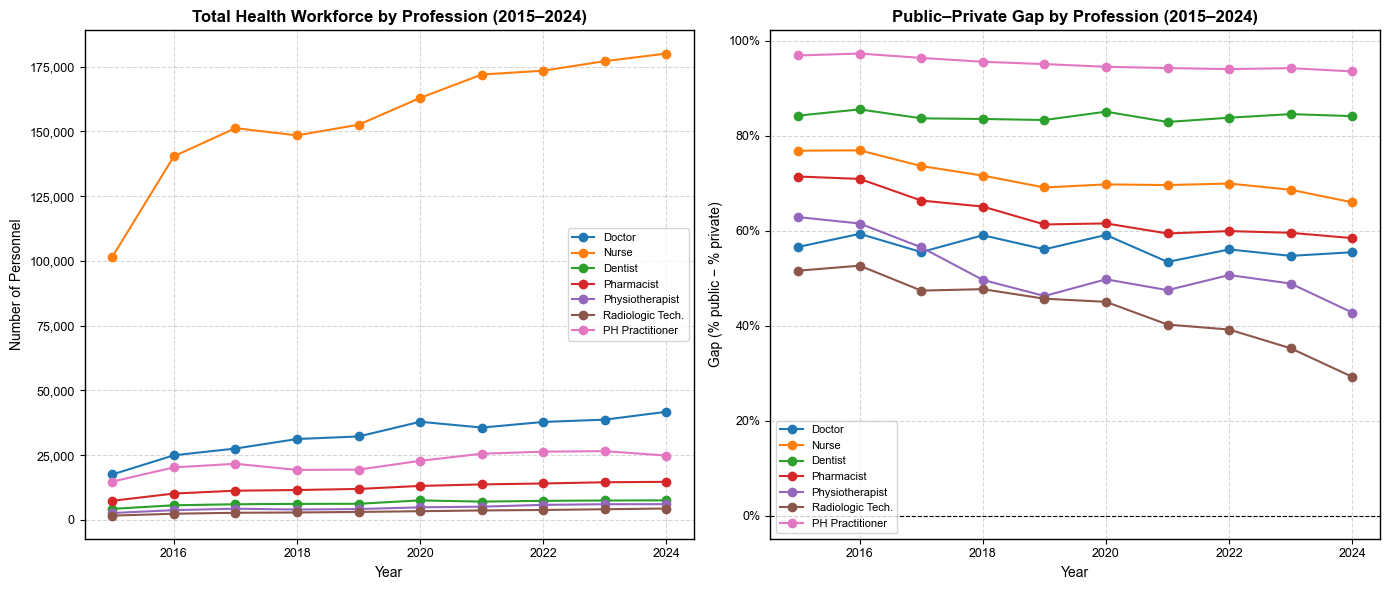

In [52]:
# Analyse the desciptive of total doctors 
df = df_foranalyse.copy()

# Create pivot data for total health workforce
total = df.pivot_table(index=['year', 'hrh'], values='total', aggfunc='sum', fill_value=0).reset_index()
public = df[df['type_gr'] == 'public'].pivot_table(index=['year', 'hrh'], values='total', aggfunc='sum', fill_value=0).reset_index()

# Merge the pivot data and calculate the ratio-to-population
total = pd.merge(total, public, how='left', on=['year', 'hrh'], suffixes=('_grand', '_public'))
total['total_private'] = total['total_grand'] - total['total_public']
total['percentage_public'] = total.apply(lambda row: f'{((row['total_public']/row['total_grand'])*100):.2f}%', axis=1)
total['percentage_private'] = total.apply(lambda row: f'{((row['total_private']/row['total_grand'])*100):.2f}%', axis=1)
total = pd.merge(total, pop_country[['year', 'pop']], how='left', on='year')
total['ratio'] = total['total_public']/(total['pop']/100000)

total.sort_values(by=['hrh', 'year'], inplace=True)
total['crude_increase_per_year'] = total.groupby('hrh')['total_grand'].diff()
total[['pct_total', 'pct_public', 'pct_private']] = total.groupby('hrh')[['total_grand', 'total_public', 'total_private']].pct_change() * 100

average_crude_increase = total.groupby('hrh')['crude_increase_per_year'].mean().reset_index()
average_changes = total.groupby('hrh')[['pct_total', 'pct_public', 'pct_private']].mean().reset_index()
average_combined = pd.merge(average_crude_increase, average_changes, how='inner', on='hrh')

total.to_csv('output/analyse/hrh/Table 1A Total Numbers of Physician and Specilist.csv')
average_changes.to_csv('output/analyse/hrh/Table 1B Changes Physician and Specilist.csv')

for gr in ['doctor', 'nurse-prof', 'dentist', 'pharmacist', 'pt', 'rt', 'ph-practictioner']:
    print(f'Descriptive Table for {gr}')
    display(total[(total['hrh'] == gr) & (total['year'].isin([2015, 2024]))][['hrh', 'total_grand', 'total_public', 'percentage_public', 'total_private', 'percentage_private']].T)
    display(average_crude_increase[average_crude_increase['hrh'] == gr].T)
    display(average_changes[average_changes['hrh'] == gr].T)

#------------------------------------------

# Build the graph
hrh_types  = ['doctor', 'nurse-prof', 'dentist', 'pharmacist', 'pt', 'rt', 'ph-practictioner']
hrh_labels = ['Doctor', 'Nurse', 'Dentist', 'Pharmacist', 'Physiotherapist', 'Radiologic Tech.', 'PH Practitioner']
colors     = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Time series of total number (total_grand) per profession
for hrh_type, label, color in zip(hrh_types, hrh_labels, colors):
    data = total[total['hrh'] == hrh_type]
    axes[0].plot(data['year'], data['total_grand'], label=label, marker='o', color=color, linewidth=1.5)

axes[0].set_title('Total Health Workforce by Profession (2015–2024)', fontsize=12, weight='bold')
axes[0].set_xlabel('Year', fontsize=10)
axes[0].set_ylabel('Number of Personnel', fontsize=10)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.5)
axes[0].tick_params(axis='both', which='major', labelsize=9)

# 2. Time series of the gap in % between public and private (% public - % private)
for hrh_type, label, color in zip(hrh_types, hrh_labels, colors):
    data = total[total['hrh'] == hrh_type].copy()
    data['gap'] = ((data['total_public'] - data['total_private']) / data['total_grand']) * 100
    axes[1].plot(data['year'], data['gap'], label=label, marker='o', color=color, linewidth=1.5)

axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Public–Private Gap by Profession (2015–2024)', fontsize=12, weight='bold')
axes[1].set_xlabel('Year', fontsize=10)
axes[1].set_ylabel('Gap (% public − % private)', fontsize=10)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0f}%'))
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.5)
axes[1].tick_params(axis='both', which='major', labelsize=9)

plt.tight_layout()
plt.savefig('output/analyse/hrh/Figure 1 HRH Trends and Public-Private Gap.png', dpi=300, bbox_inches='tight')
plt.show()

In [53]:
# Analyse the health regions, provincial, and district levels

df = df_foranalyse.copy()
df['dist_id'] = df['dist_id'].astype(int).astype(str)
df['type_gr'] = df['htype'].apply(lambda x: 'private' if x == 'โรงพยาบาลเอกชน' else 'public')

df_public = df[df['type_gr'] == 'public']

# Region level
df_hregion = df_public.pivot_table(index=['year', 'hregion', 'hrh'], values='total', aggfunc='sum', fill_value=0).reset_index()
df_hregion = pd.merge(df_hregion, pop_hregion[['year', 'hregion', 'pop']], how='left', on=['year', 'hregion'])
df_hregion['den'] = df_hregion['total']/(df_hregion['pop']/100000)
df_hregion.to_csv('output/analyse/hrh/Table 2 Density in health region level.csv')

# Province level
df_prov = df_public.pivot_table(index=['year', 'prov', 'hrh'], values='total', aggfunc='sum', fill_value=0).reset_index()
df_prov = pd.merge(df_prov, pop_prov[['year', 'prov', 'pop']], how='left', on=['year', 'prov'])
df_prov['den'] = df_prov['total']/(df_prov['pop']/100000)
df_prov.to_csv('output/analyse/hrh/Table 3 Density in provincial level.csv')

# District level
df_dist = df_public.pivot_table(index=['year', 'dist_id', 'hrh'], values='total', aggfunc='sum', fill_value=0).reset_index()
df_dist = pd.merge(df_dist, pop_dist[['year', 'dist_id', 'pop']], how='left', on=['year', 'dist_id'])
df_dist['den'] = df_dist['total']/(df_dist['pop']/100000)
df_dist.to_csv('output/analyse/hrh/Table 4 Density in district level.csv')

In [56]:
def run_coverage_inequity(df_public, df_hregion, df_prov, df_dist, years):
    result_cov = []
    result_ineq = []

    for year in years:
        df_y = df_public[df_public['year'] == year]

        for hrh in sorted(df_public['hrh'].unique()):
            df_hrh = df_y[df_y['hrh'] == hrh]

            # --- Coverage ---
            result_cov.append({
                'year': year,
                'hrh': hrh,
                'n_hrh': df_hrh['total'].sum(),
                'cov_hregion': analyse.coverage(df_hregion.query("year==@year & hrh==@hrh"), 'total', 'hregion'),
                'cov_prov': analyse.coverage(df_prov.query("year==@year & hrh==@hrh"), 'total', 'prov'),
                'cov_dist': analyse.coverage(df_dist.query("year==@year & hrh==@hrh"), 'total', 'dist')
            })

            # --- Inequity ---
            result_ineq.append({
                'year': year,
                'hrh': hrh,
                'G_hregion': analyse.gini(df_hregion.query("year==@year & hrh==@hrh"), 'total', 'pop'),
                'G_prov': analyse.gini(df_prov.query("year==@year & hrh==@hrh"), 'total', 'pop'),
                'G_dist': analyse.gini(df_dist.query("year==@year & hrh==@hrh"), 'total', 'pop'),
                'T_hregion': analyse.theil_T(df_hregion.query("year==@year & hrh==@hrh"), 'total', 'pop'),
                'T_prov': analyse.theil_T(df_prov.query("year==@year & hrh==@hrh"), 'total', 'pop'),
                'T_dist': analyse.theil_T(df_dist.query("year==@year & hrh==@hrh"), 'total', 'pop')
            })

    return pd.DataFrame(result_cov), pd.DataFrame(result_ineq)

In [58]:
years = range(2015, 2025)
cov_imp, ineq_imp = run_coverage_inequity(
    df_public[df_public['hrh'].isin(hrh_types)], df_hregion, df_prov, df_dist, years
)

display("Coverage analysis", cov_imp.head())
display("Inequity analysis", ineq_imp.head())

cov_imp.to_csv('output/analyse/hrh/Table 5 Coverage of Specialists.csv')
ineq_imp.to_csv('output/analyse/hrh/Table 6 Inequity distribution of Specialist.csv')

'Coverage analysis'

,year,hrh,n_hrh,cov_hregion,cov_prov,cov_dist
0,2015,dentist,3942.0,13 (100.00%),77 (100.00%),706 (76.08%)
1,2015,doctor,13750.0,13 (100.00%),77 (100.00%),715 (77.05%)
2,2015,nurse-prof,89825.0,13 (100.00%),77 (100.00%),857 (92.35%)
3,2015,ph-practictioner,14577.0,13 (100.00%),77 (100.00%),843 (90.84%)
4,2015,pharmacist,6336.0,13 (100.00%),77 (100.00%),712 (76.72%)


'Inequity analysis'

,year,hrh,G_hregion,G_prov,G_dist,T_hregion,T_prov,T_dist
0,2015,dentist,0.170277,0.271376,0.440779,0.049246,0.122438,0.406560
1,2015,doctor,0.203475,0.322158,0.633752,0.066664,0.174424,0.889708
2,2015,nurse-prof,0.127136,0.232591,0.487096,0.025224,0.088269,0.496065
3,2015,ph-practictioner,0.161029,0.275654,0.353222,0.080218,0.139659,0.229598
4,2015,pharmacist,0.086459,0.195171,0.460587,0.012630,0.064119,0.455174
